# Solar India · 01 Data
How much solar energy reaches the ground in Indian cities, and what decides it?
This notebook downloads daily NASA POWER data from 2015 up to the present for 22 cities, cleans it and builds the targets.
Output: `data/solar.csv`.

In [1]:
import time
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)

Project root: /Users/krishkalsi/Desktop/solar-india


## Cities

In [2]:
# 22 cities covering every climate of India: desert, coast, monsoon belt, plains, hills and the cold north.
cities = pd.DataFrame([
    ("Delhi", 28.61, 77.21, "North plains"),
    ("Lucknow", 26.85, 80.95, "North plains"),
    ("Patna", 25.59, 85.14, "North plains"),
    ("Chandigarh", 30.73, 76.78, "North plains"),
    ("Jaipur", 26.91, 75.79, "Desert"),
    ("Jodhpur", 26.24, 73.02, "Desert"),
    ("Bhuj", 23.24, 69.67, "Desert"),
    ("Ahmedabad", 23.02, 72.57, "West"),
    ("Mumbai", 19.08, 72.88, "West coast"),
    ("Pune", 18.52, 73.86, "Deccan"),
    ("Bengaluru", 12.97, 77.59, "Deccan"),
    ("Hyderabad", 17.39, 78.49, "Deccan"),
    ("Nagpur", 21.15, 79.09, "Central"),
    ("Bhopal", 23.26, 77.41, "Central"),
    ("Chennai", 13.08, 80.27, "East coast"),
    ("Bhubaneswar", 20.30, 85.82, "East coast"),
    ("Kolkata", 22.57, 88.36, "East coast"),
    ("Thiruvananthapuram", 8.52, 76.94, "South coast"),
    ("Guwahati", 26.14, 91.74, "North-East"),
    ("Shillong", 25.58, 91.89, "North-East"),
    ("Srinagar", 34.08, 74.80, "Himalaya"),
    ("Leh", 34.15, 77.58, "Himalaya"),
], 
columns=["city", "lat", "lon", "region"])
cities

,city,lat,lon,region
0,Delhi,28.61,77.21,North plains
1,Lucknow,26.85,80.95,North plains
2,Patna,25.59,85.14,North plains
3,Chandigarh,30.73,76.78,North plains
4,Jaipur,26.91,75.79,Desert
5,Jodhpur,26.24,73.02,Desert
6,Bhuj,23.24,69.67,Desert
7,Ahmedabad,23.02,72.57,West
8,Mumbai,19.08,72.88,West coast
9,Pune,18.52,73.86,Deccan


## Download from NASA POWER

In [3]:
POWER_URL = "https://power.larc.nasa.gov/api/temporal/daily/point"

PARAMETERS = {
    "ALLSKY_SFC_SW_DWN": "solar",          # sunlight reaching the ground (kWh/m^2/day)  <- what we predict
    "CLRSKY_SFC_SW_DWN": "clear_sky",      # sunlight there would be with no clouds (kWh/m^2/day)
    "CLOUD_AMT": "cloud",                  # cloud cover (%)
    "T2M": "temp",                         # mean temperature at 2 m (C)
    "T2M_MAX": "temp_max",
    "T2M_MIN": "temp_min",
    "T2MDEW": "dew_point",                 # dew point (C)
    "RH2M": "humidity",                    # relative humidity (%)
    "QV2M": "specific_humidity",           # water vapour (g/kg)
    "PRECTOTCORR": "rain",                 # rainfall (mm/day)
    "WS2M": "wind",                        # wind speed at 2 m (m/s)
    "PS": "pressure",                      # surface pressure (kPa)
}

# NASA publishes the solar measurements a few days late, so we stop one week before today.
END_DATE = (pd.Timestamp.today() - pd.Timedelta(days=7)).strftime("%Y%m%d")
print("Downloading up to:", END_DATE)

def fetch_power(lat, lon, start="20150101", end=END_DATE):
    params = {
        "parameters": ",".join(PARAMETERS),
        "community": "RE",
        "latitude": lat,
        "longitude": lon,
        "start": start,
        "end": end,
        "format": "JSON",
    }
    r = requests.get(POWER_URL, params=params, timeout=120)
    r.raise_for_status()
    values = r.json()["properties"]["parameter"]       # {parameter: {"20150101": value, ...}}
    df = pd.DataFrame(values)
    df.index = pd.to_datetime(df.index, format="%Y%m%d")
    return df.rename(columns=PARAMETERS)

test = fetch_power(19.08, 72.88, "20240101", "20240107")    # one week in Mumbai, as a test
test

,solar,clear_sky,cloud,temp,temp_max,temp_min,dew_point,humidity,specific_humidity,rain,wind,pressure
2024-01-01,4.0138,4.0649,13.34,24.68,32.80,18.83,15.75,60.93,11.24,0.00,1.64,100.18
2024-01-02,4.0087,4.0675,13.51,24.09,32.39,18.17,14.99,59.98,10.70,0.00,1.64,100.12
2024-01-03,3.8227,3.8724,16.69,23.56,31.84,17.70,14.39,58.83,10.30,0.00,1.92,100.05
2024-01-04,4.2718,4.3558,17.09,22.72,30.19,17.74,12.67,56.52,9.22,0.00,1.58,100.12
2024-01-05,4.2247,4.2840,19.17,21.44,29.32,15.48,11.60,58.20,8.63,0.00,1.61,100.16
2024-01-06,3.9379,3.9509,17.51,23.06,32.18,16.18,13.99,59.31,10.11,0.00,2.19,100.07
2024-01-07,4.1304,4.4014,41.40,24.34,31.75,18.75,17.15,66.73,12.30,0.02,2.28,100.09


In [4]:
# One request per city, saved to data/raw/<city>.csv. Re-running skips cities already downloaded.
for _, c in cities.iterrows():
    path = RAW_DIR / f"{c['city']}.csv"
    if path.exists():
        print(f"{c['city']:<20} already downloaded")
        continue
    df = fetch_power(c["lat"], c["lon"])
    df.to_csv(path, index_label="date")
    print(f"{c['city']:<20} {len(df)} days")
    time.sleep(1)

Delhi                4310 days
Lucknow              4310 days
Patna                4310 days
Chandigarh           4310 days
Jaipur               4310 days
Jodhpur              4310 days
Bhuj                 4310 days
Ahmedabad            4310 days
Mumbai               4310 days
Pune                 4310 days
Bengaluru            4310 days
Hyderabad            4310 days
Nagpur               4310 days
Bhopal               4310 days
Chennai              4310 days
Bhubaneswar          4310 days
Kolkata              4310 days
Thiruvananthapuram   4310 days
Guwahati             4310 days
Shillong             4310 days
Srinagar             4310 days
Leh                  4310 days


In [5]:
frames = []
for _, c in cities.iterrows():
    df = pd.read_csv(RAW_DIR / f"{c['city']}.csv", parse_dates=["date"])
    df["city"], df["lat"], df["lon"], df["region"] = c["city"], c["lat"], c["lon"], c["region"]
    frames.append(df)
data = pd.concat(frames, ignore_index=True)
print(data.shape)
data.head()

(94820, 17)


,date,solar,clear_sky,cloud,temp,temp_max,temp_min,dew_point,humidity,specific_humidity,rain,wind,pressure,city,lat,lon,region
0,2015-01-01,2.1614,3.4766,74.58,15.08,23.90,8.07,2.69,44.51,4.78,0.02,1.19,99.29,Delhi,28.61,77.21,North plains
1,2015-01-02,0.8503,3.5364,97.51,15.76,21.34,11.84,7.61,59.67,6.59,3.90,1.16,99.39,Delhi,28.61,77.21,North plains
2,2015-01-03,1.3795,3.5808,77.10,14.41,20.72,8.65,10.06,76.62,7.75,10.12,0.96,99.38,Delhi,28.61,77.21,North plains
3,2015-01-04,2.1077,2.9947,36.39,13.53,21.50,8.12,5.43,62.98,5.79,0.00,2.20,99.46,Delhi,28.61,77.21,North plains
4,2015-01-05,3.5978,3.6024,5.28,13.07,22.76,6.59,0.14,44.10,3.90,0.00,3.89,99.18,Delhi,28.61,77.21,North plains


## Cleaning

In [6]:
# NASA POWER marks a missing value with -999
data = data.replace(-999, np.nan)
print("Missing values per column:")
print(data.isnull().sum()[data.isnull().sum() > 0])
print("\nDuplicate rows:", data.duplicated(subset=["city", "date"]).sum())

Missing values per column:
clear_sky    1595
cloud        1782
dtype: int64

Duplicate rows: 0


In [7]:
# Short gaps in the weather columns are filled from the neighbouring days of the same city.
# Days with no solar measurement are dropped: that is what we predict, so it cannot be guessed.
weather_cols = [v for v in PARAMETERS.values() if v != "solar"]
data = data.sort_values(["city", "date"])
data[weather_cols] = data.groupby("city")[weather_cols].transform(lambda s: s.interpolate(limit=3))
data = data.dropna().reset_index(drop=True)
print("Rows after cleaning:", len(data))

Rows after cleaning: 93104


## Targets

In [8]:
# Regression target: solar energy reaching the ground (kWh per m^2 per day).
# Classification target: how sunny the day was compared with a perfectly clear day.
data["clearness"] = data["solar"] / data["clear_sky"]          # 1 = no clouds at all

data["day_type"] = pd.cut(data["clearness"], bins=[0, 0.5, 0.75, 2], labels=["poor", "average", "good"])
print(data["day_type"].value_counts(normalize=True).round(3))

data["month"] = data["date"].dt.month
data["day_of_year"] = data["date"].dt.day_of_year
data["year"] = data["date"].dt.year

day_type
good       0.733
average    0.182
poor       0.085
Name: proportion, dtype: float64


/var/folders/61/9_bd7j9j0rx2v0c23wplfm180000gn/T/ipykernel_75888/1137539577.py:9: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  data["day_of_year"] = data["date"].dt.dayofyear


## Split by time

In [9]:
# Test = the most recent 12 months, validation = the 12 months before that, train = everything earlier.
last_day = data["date"].max()
TEST_START = last_day - pd.DateOffset(months=12) + pd.Timedelta(days=1)
VAL_START = TEST_START - pd.DateOffset(months=12)

data["split"] = "train"
data.loc[data["date"] >= VAL_START, "split"] = "val"
data.loc[data["date"] >= TEST_START, "split"] = "test"
print(data.groupby("split", sort=False)["date"].agg(["min", "max", "count"]))

             min        max  count
split                             
train 2015-01-01 2024-08-02  77044
val   2024-08-03 2025-08-02   8030
test  2025-08-03 2026-08-02   8030


## First look

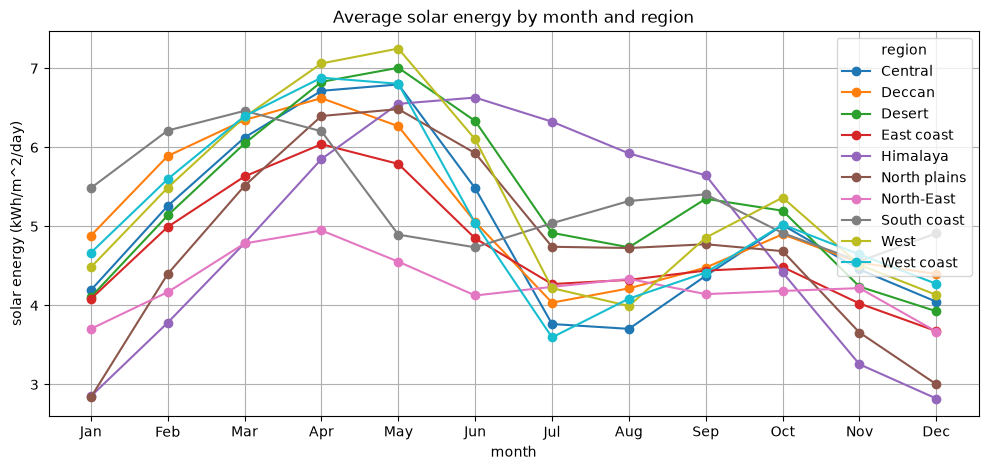

In [10]:
monthly = data.groupby(["region", "month"])["solar"].mean().unstack(0)
monthly.plot(figsize=(12, 5), marker="o")
plt.ylabel("solar energy (kWh/m^2/day)")
plt.title("Average solar energy by month and region")
plt.xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
plt.grid()
plt.show()

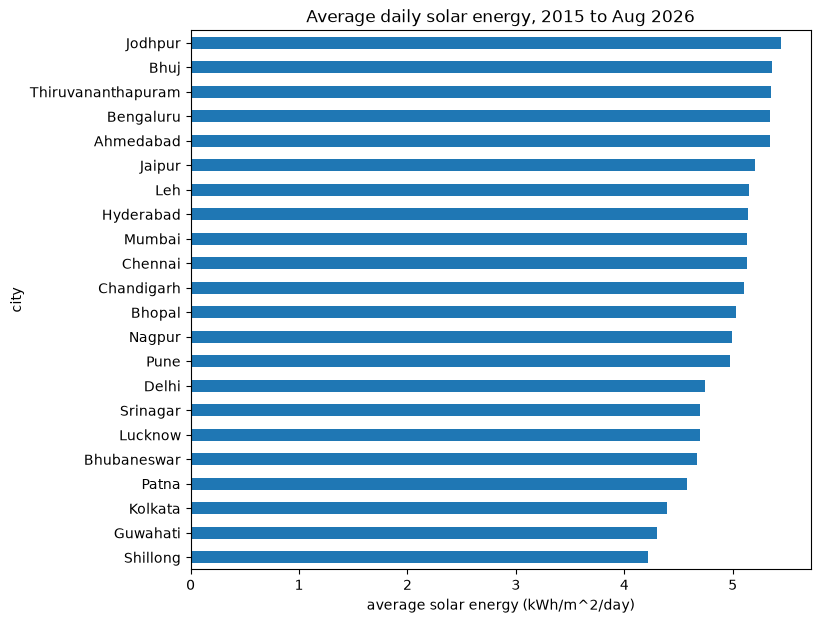

In [11]:
city_mean = data.groupby("city")["solar"].mean().sort_values()
city_mean.plot.barh(figsize=(8, 7))
plt.xlabel("average solar energy (kWh/m^2/day)")
plt.title(f"Average daily solar energy, 2015 to {data['date'].max():%b %Y}")
plt.show()

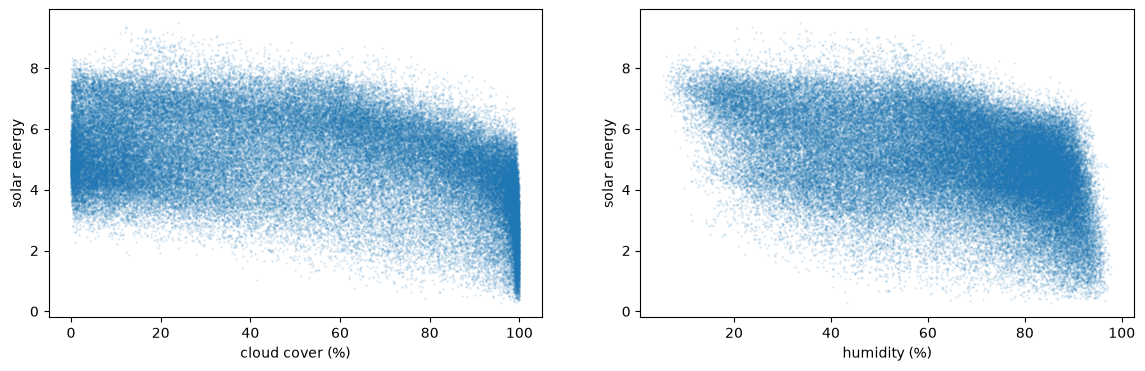

In [12]:
fig = plt.figure(figsize=(14, 4))
ax = fig.add_subplot(1, 2, 1)
ax.scatter(data["cloud"], data["solar"], s=1, alpha=0.1)
ax.set_xlabel("cloud cover (%)")
ax.set_ylabel("solar energy")
ax = fig.add_subplot(1, 2, 2)
ax.scatter(data["humidity"], data["solar"], s=1, alpha=0.1)
ax.set_xlabel("humidity (%)")
ax.set_ylabel("solar energy")
plt.show()

In [13]:
data.to_csv(DATA_DIR / "solar.csv", index=False)
print("Saved solar.csv:", data.shape)

Saved solar.csv: (93104, 23)
